# Load-shedding risk early warning (Bangladesh)

ML Lab project, Dept. of CSE, University of Asia Pacific

Swagoto Utsab Singha Roy (23101124), Lamiya Zaman (23101132), Jannatul Ferdoushi Islam (23101119)

This notebook runs our project on Kaggle. It gets the code from our GitHub repo, checks the saved models, runs the tests and then goes through the steps one by one: data, baselines, the GRU model, the final ensemble and the lab experiments. At the end there is a small demo where you can pick a date and see the forecast.


In [29]:
# settings
REPO_URL = "https://github.com/Spirekharn/loadshed_early_warning.git"
RETRAIN  = False   # True = train all models again, False = use the saved models from the repo
QUICK    = False   # only used when RETRAIN is True: 1 seed and 10 epochs instead of 3 seeds
RUN_LONG = False   # ablation + leave-one-division-out (step 5), this is the slowest part

In [30]:
import os, sys, glob, shutil, subprocess
from pathlib import Path

def find_project():
    # running on our own laptop from inside the repo
    for p in [Path.cwd(), Path.cwd().parent]:
        if (p / "src" / "config.py").exists():
            return p
    work = Path("/kaggle/working/loadshed-early-warning")
    if (work / "src" / "config.py").exists():      # already cloned earlier in this session
        return work
    # repo added as a Kaggle dataset (input folder is read only so we copy it)
    hits = glob.glob("/kaggle/input/**/src/config.py", recursive=True)
    if hits:
        shutil.copytree(Path(hits[0]).parents[1], work)
        return work
    # otherwise clone it from GitHub
    r = subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(work)])
    if r.returncode != 0:
        raise RuntimeError("Could not clone the repo. Turn on Internet in the notebook settings "
                           "(needs a verified phone number) or add the repo as a dataset.")
    return work

ROOT = find_project()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
print("project folder:", ROOT)
print(sorted(p.name for p in ROOT.iterdir()))

project folder: /kaggle/working/loadshed-early-warning
['.git', '.gitignore', '.streamlit', 'README.md', 'dashboard', 'data', 'notebooks', 'outputs', 'report', 'requirements.txt', 'requirements_frozen.txt', 'scripts', 'src', 'tests']


In [31]:
# Kaggle has most of these already, holidays sometimes needs to be installed
try:
    import holidays
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "holidays"], check=True)
import numpy as np, pandas as pd, torch, xgboost, sklearn, shap
print("python", sys.version.split()[0], "| torch", torch.__version__, "| xgboost", xgboost.__version__,
      "| sklearn", sklearn.__version__, "| pandas", pd.__version__)
pd.set_option("display.width", 220, "display.max_columns", 40)
from IPython.display import Image, display, Markdown
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"

def show(*names, width=900):
    for n in names:
        f = FIG / n
        if f.exists(): display(Image(str(f), width=width))
        else: print("missing figure:", n)

def run(script, *args):
    # runs one of our scripts and prints the end of its output
    r = subprocess.run([sys.executable, f"scripts/{script}", *args], capture_output=True, text=True)
    print(r.stdout[-6000:]); print(r.stderr[-3000:] if r.returncode else "")
    if r.returncode: raise RuntimeError(f"{script} failed")

Q = ["--quick"] if QUICK else []

python 3.13.18 | torch 2.11.0+cpu | xgboost 3.4.1 | sklearn 1.6.1 | pandas 2.3.3


## Step 0: check the saved models
The repo has our trained models in `outputs/models`. This runs them on the test set again and compares with the predictions we saved during training. The difference should be basically zero (around 1e-6).

In [32]:
run("check_saved_models.py")

seed 42:  T+1: max|torch - saved| = 2.38e-06, macro-F1 = 0.582  T+3: max|torch - saved| = 2.38e-06, macro-F1 = 0.490  | numpy copy max diff = 2.99e-06
seed 43:  T+1: max|torch - saved| = 3.81e-06, macro-F1 = 0.553  T+3: max|torch - saved| = 3.81e-06, macro-F1 = 0.511  | numpy copy max diff = 3.20e-06
seed 44:  T+1: max|torch - saved| = 1.91e-06, macro-F1 = 0.643  T+3: max|torch - saved| = 1.91e-06, macro-F1 = 0.495  | numpy copy max diff = 2.06e-06

If every difference is tiny, the saved models are the ones that produced the reported results.




## Step 1: leakage tests
Checks that the split is by date, recomputes 300 random labels from the raw data, and scrambles all the data after 2024 to make sure the training data, labels and thresholds don't change. Also checks that no NaN goes into the model.

In [33]:
r = subprocess.run([sys.executable, "tests/test_pipeline.py"], capture_output=True, text=True); print(r.stdout, r.stderr[-2000:])

NOTE: 'Minimum Generation Forecast' is missing in the newest data -> feature DROPPED (fcst_min_gen, fcst_ratio)
OK  split boundaries
OK  300 random targets recomputed from raw data
NOTE: 'Minimum Generation Forecast' is missing in the newest data -> feature DROPPED (fcst_min_gen, fcst_ratio)
OK  future-perturbation: train/val features, labels and thresholds are unaffected by test-period data
OK  no NaN in model inputs

ALL TESTS PASSED
 


## Step 2: data, labels and 14-day windows
Low = no load shedding, Medium = shedding/demand is below the threshold, High = above it. The threshold is the median of the non-zero ratios in the training years only (7.6% for the zones, 1.9% for national).

NOTE: 'Minimum Generation Forecast' is missing in the newest data -> feature DROPPED (fcst_min_gen, fcst_ratio)
Samples: 24920 | windows: (24920, 14, 13) | weather feats: ['temp', 'temp_roll3', 'temp_d1', 't2m', 'rh2m', 'prec', 'prec_roll3']
Thresholds: {'zone_ratio': 0.07600950118764846, 'national_ratio': 0.019487525286581254}
  train n=14770  2019-12-04 -> 2023-12-28  T+1 L/M/H=[12986, 855, 849]  T+3 L/M/H=[12976, 851, 853]  
  val   n= 3480  2023-12-29 -> 2024-12-28  T+1 L/M/H=[2538, 508, 414]  T+3 L/M/H=[2524, 505, 411]  
  test  n= 6660  2024-12-29 -> 2026-10-27  T+1 L/M/H=[4520, 1221, 899]  T+3 L/M/H=[4499, 1227, 894]  

Class counts by year (T+1):
 y1     Low  Medium  High
year                    
2019   280       0     0
2020  3607       0     3
2021  3643       6     1
2022  2927     267   456
2023  2559     582   389
2024  2538     508   414
2025  2978     565    87
2026  1512     656   812

STEP 1 DONE. Check outputs/figures and data/processed.




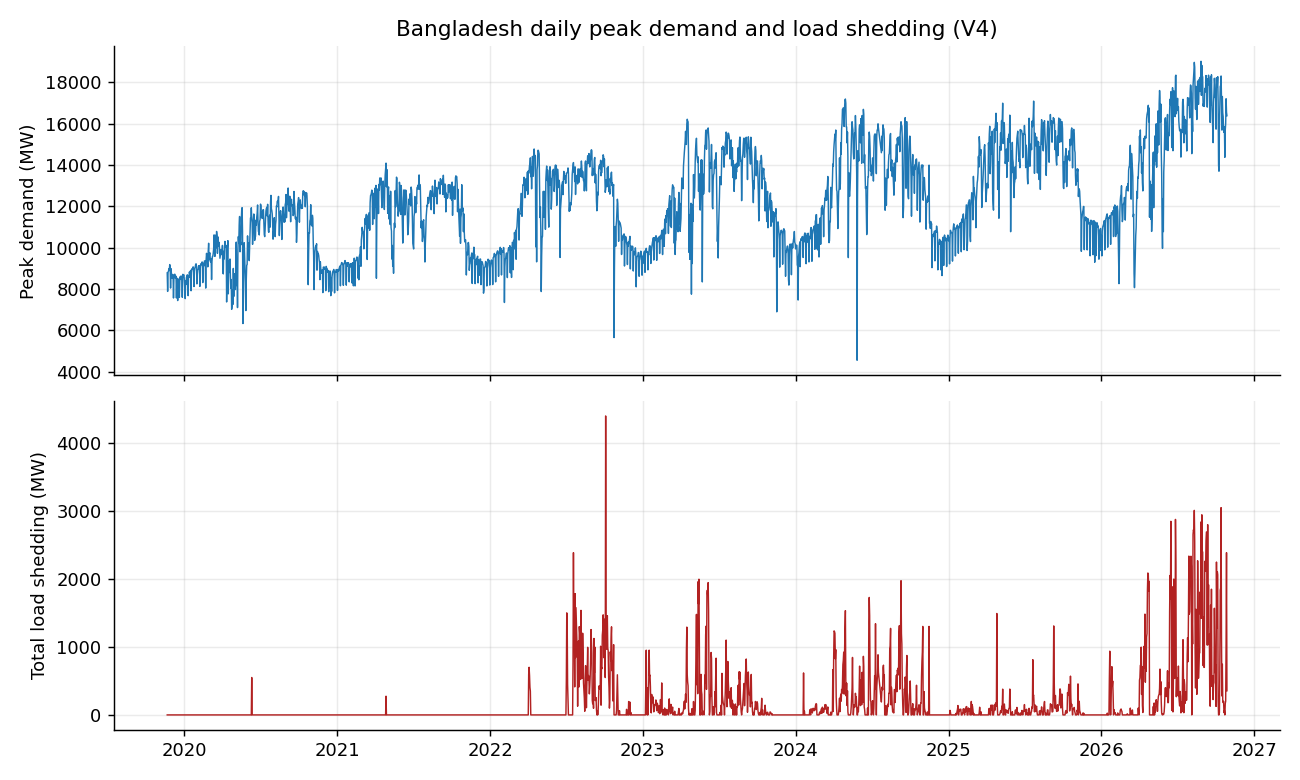

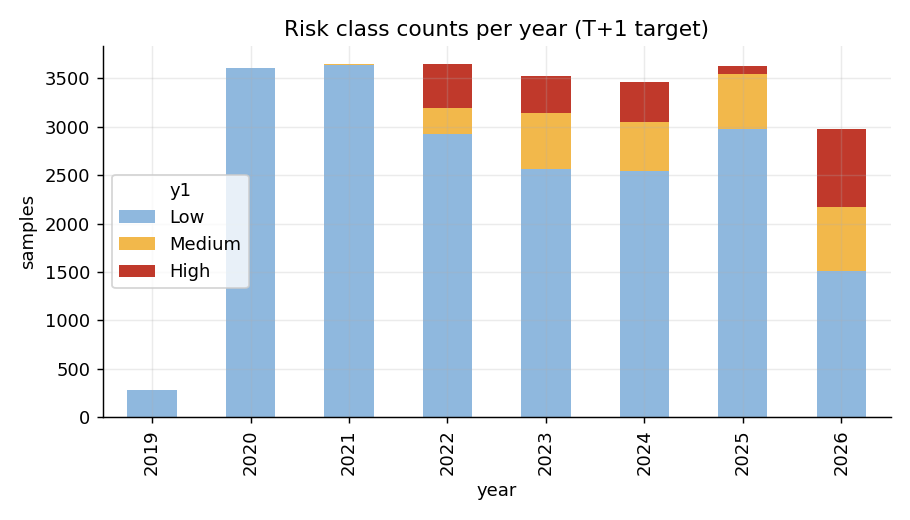

,year,Low,Medium,High
0,2019,280,0,0
1,2020,3607,0,3
2,2021,3643,6,1
3,2022,2927,267,456
4,2023,2559,582,389
5,2024,2538,508,414
6,2025,2978,565,87
7,2026,1512,656,812


In [34]:
run("01_prepare.py")
show("eda_demand_shedding.png", "eda_class_counts.png")
pd.read_csv(TAB / "class_counts_by_year_T+1.csv")

## Step 3: baselines
Persistence (tomorrow is the same as today), a simple rule using BPDB's reserve margin, logistic regression, random forest and XGBoost. The SHAP plot shows which features XGBoost uses most.

,model,horizon,macro_f1,high_recall,high_precision,missed_high,false_alarm
2,Persistence,T+1,0.701,0.690,0.690,279,279
5,Rule(BPDB forecast),T+1,0.530,0.805,0.464,175,836
8,LogReg,T+1,0.442,0.858,0.352,128,1420
11,RandomForest,T+1,0.643,0.603,0.646,357,297
14,XGBoost,T+1,0.620,0.527,0.658,425,246
17,Persistence,T+3,0.606,0.551,0.564,401,381
20,Rule(BPDB forecast),T+3,0.474,0.702,0.397,266,952
23,LogReg,T+3,0.336,0.668,0.254,297,1752
26,RandomForest,T+3,0.451,0.100,0.357,805,160
29,XGBoost,T+3,0.495,0.262,0.441,660,297


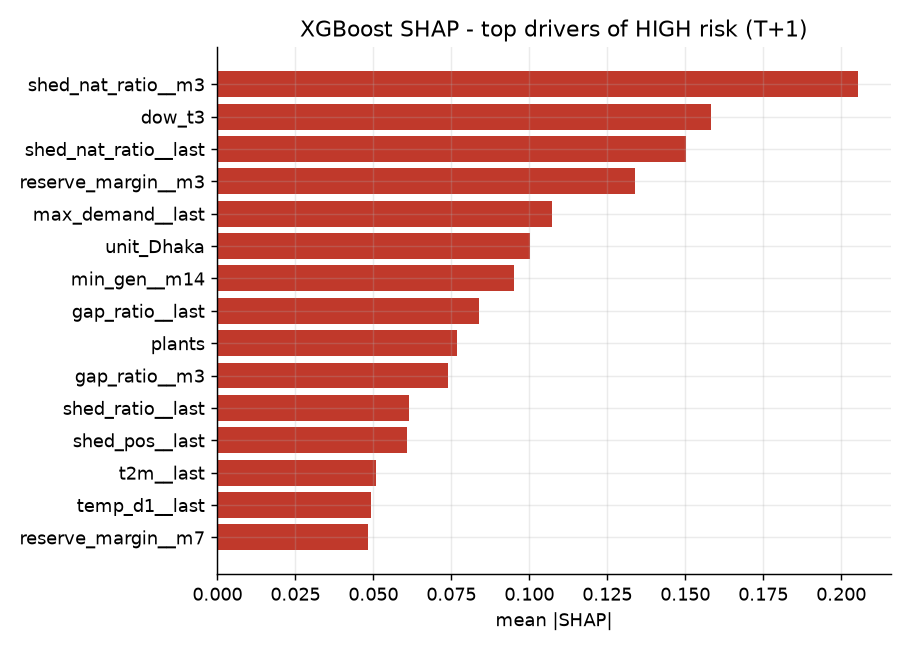

In [35]:
if RETRAIN: run("03_baselines.py")
b = pd.read_csv(TAB / "baselines_test_metrics.csv")
display(b[b.group == "All"][["model", "horizon", "macro_f1", "high_recall", "high_precision", "missed_high", "false_alarm"]].round(3))
show("shap_top_T+1.png")

## Step 4: multimodal GRU
Our main model. One GRU reads the grid data, another reads the weather, and a small MLP takes the context (holidays, gas/coal limits, plants in maintenance). Attention combines the three and there are two outputs, T+1 and T+3. It is trained with 3 seeds and early stopping on validation macro-F1. After that we do temperature scaling and choose the abstain threshold, both on the 2024 validation data.

macro_f1        bal_acc        high_recall        high_precision        missed_high         false_alarm             ece         brier        coverage       
                                                  mean    std    mean    std        mean    std           mean    std        mean     std        mean      std   mean    std   mean    std     mean    std
model                                 horizon                                                                                                                                                             
MM-GRU calibrated                     T+1        0.593  0.046   0.657  0.036       0.760  0.069          0.459  0.053     215.333  61.785     816.000  166.096  0.040  0.013  0.424  0.042      NaN    NaN
                                      T+3        0.499  0.011   0.564  0.014       0.690  0.038          0.312  0.014     277.333  34.020    1367.333  149.346  0.061  0.007  0.505  0.020      NaN    NaN
MM-GRU calibrated+abstain (kept only) T+1        0.695  0.037   0.741  0.019       0.891  0.039          0.622  0.079      63.333  22.502     330.667  127.563    NaN    NaN    NaN    NaN    0.631  0.024
                                      T+3        0.569  0.004   0.632  0.018       0.778  0.071          0.393  0.015     126.667  50.895     672.000   14.000    NaN    NaN    NaN    NaN    0.655  0.034
MM-GRU raw                            T+1        0.593  0.046   0.657  0.036       0.760  0.069          0.459  0.053     215.333  61.785     816.000  166.096  0.123  0.072  0.458  0.071      NaN    NaN
                                      T+3        0.499  0.011   0.564  0.014       0.690  0.038          0.312  0.014     277.333  34.020    1367.333  149.346  0.184  0.045  0.572  0.048      NaN    NaN

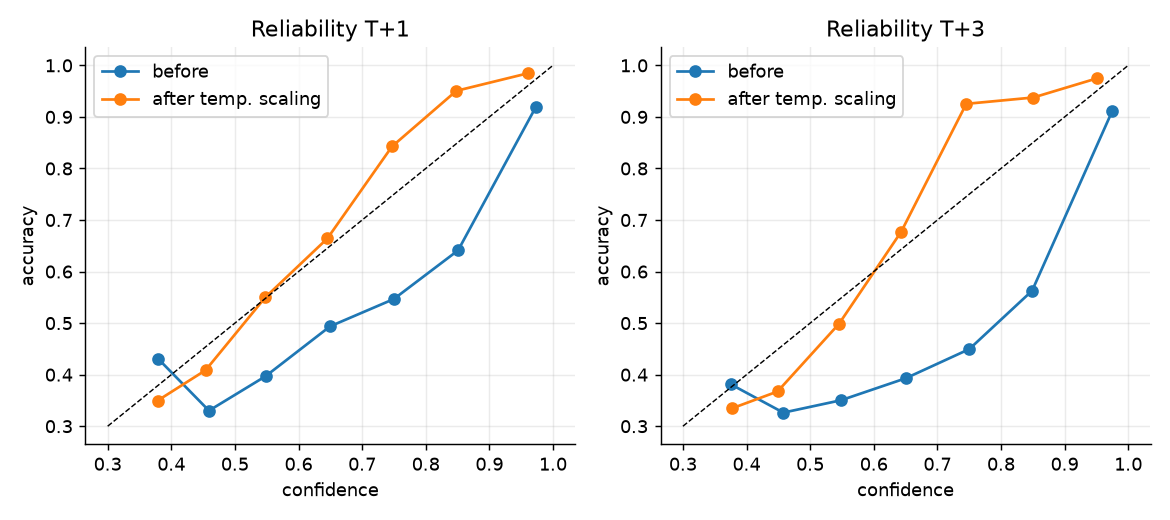

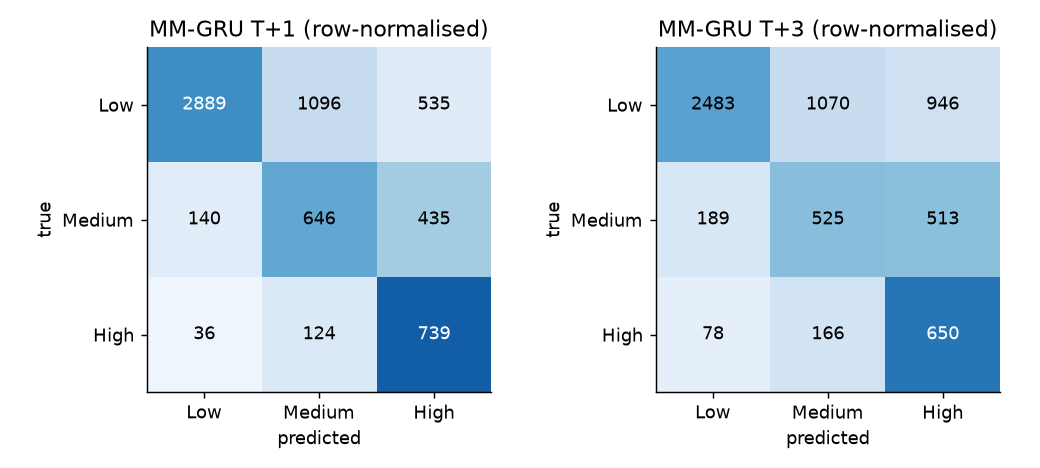

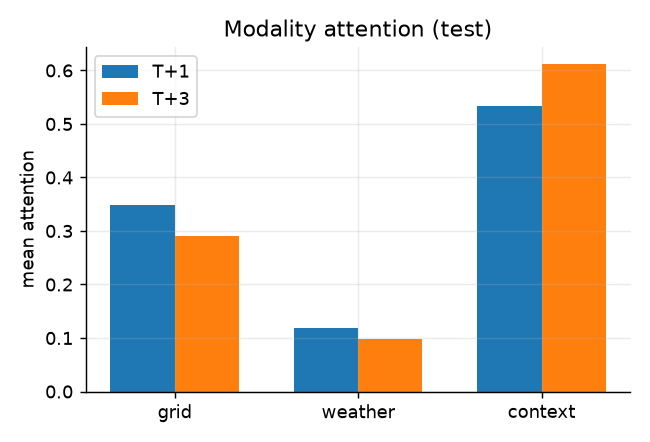

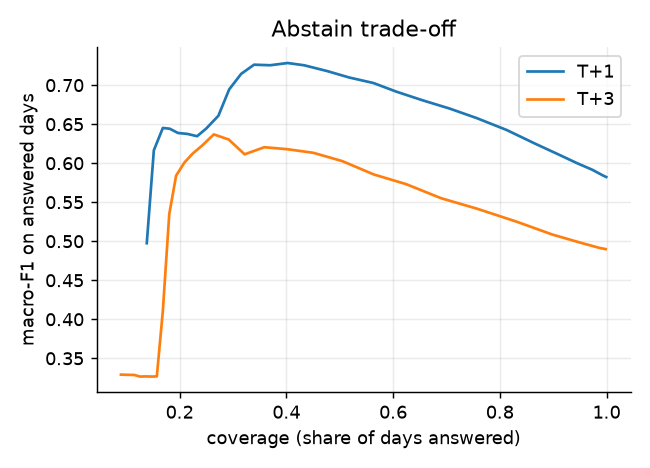

In [36]:
if RETRAIN: run("04_train_nn.py", *Q)
display(pd.read_csv(TAB / "nn_test_metrics_mean_std.csv", header=[0, 1], index_col=[0, 1]).round(3))
show("calibration_reliability.png", "confusion_mmgru.png", "modality_attention.png", "abstain_coverage_curve.png", width=700)

## Step 5: modality ablation and leave-one-division-out
This is slow so it only trains when both `RETRAIN` and `RUN_LONG` are True. Otherwise it just shows our saved results.

,model,horizon,macro_f1,high_recall,missed_high,false_alarm
0,FULL (grid+weather+context),T+1,0.582,0.822,160,970
1,FULL (grid+weather+context),T+3,0.490,0.727,244,1459
2,grid only,T+1,0.598,0.749,226,473
3,grid only,T+3,0.509,0.686,281,671
4,weather only,T+1,0.435,0.339,594,923
5,weather only,T+3,0.397,0.484,461,1516
6,context only,T+1,0.396,0.473,474,1669
7,context only,T+3,0.378,0.396,540,1587
8,without grid,T+1,0.477,0.533,420,1078
9,without grid,T+3,0.460,0.601,357,1482


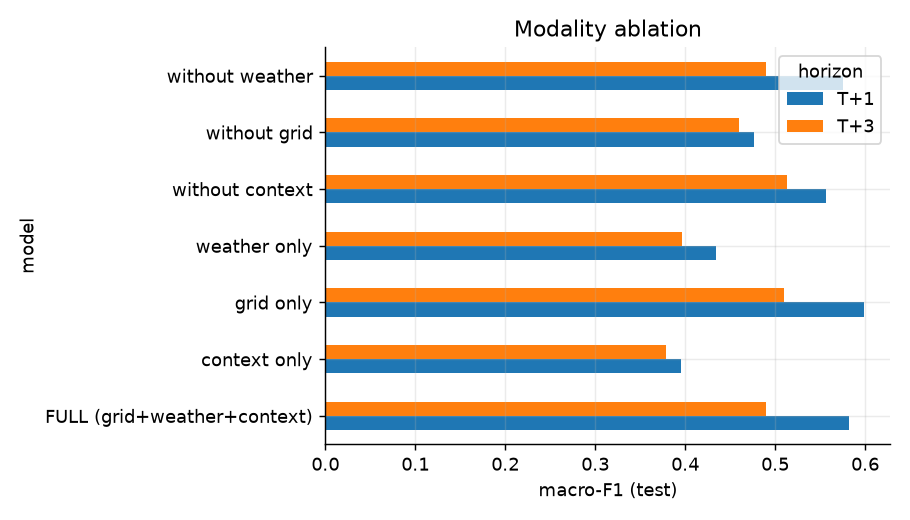

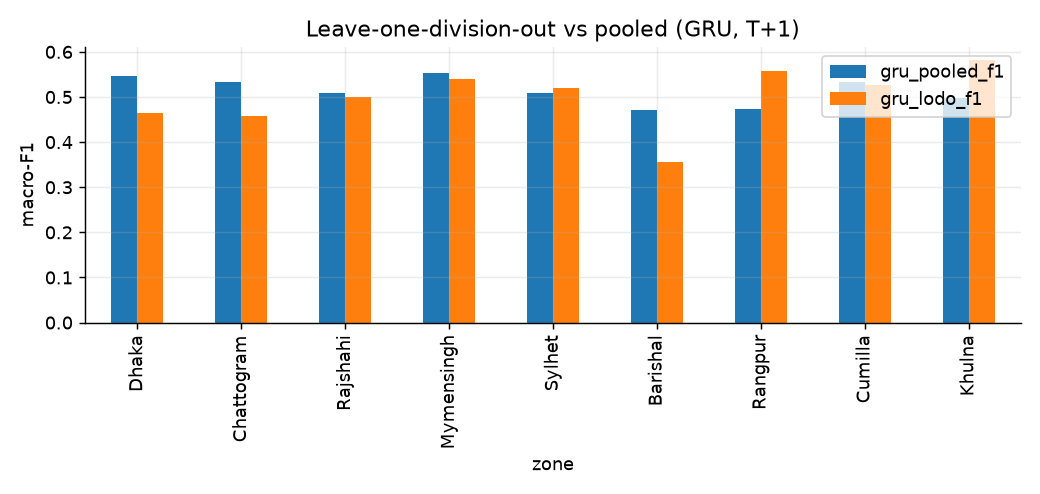

In [37]:
if RETRAIN and RUN_LONG: run("05_ablation_lodo.py", *Q)
display(pd.read_csv(TAB / "ablation_modalities.csv")[["model", "horizon", "macro_f1", "high_recall", "missed_high", "false_alarm"]].round(3))
show("ablation_modalities.png", "lodo_T+1.png", width=700)

## Step 6: final ensemble
The final alert mixes the GRU, XGBoost and persistence. The weights are picked on the 2024 validation data, then the models are retrained on 2019-2024 and tested once on 2025-2026. It also makes the latest forecast.

,model,horizon,macro_f1,bal_acc,high_recall,high_precision,missed_high,false_alarm,ece,coverage
0,Persistence,T+1,0.701,0.701,0.690,0.690,279,279,NaN,NaN
1,Persistence,T+3,0.606,0.604,0.551,0.564,401,381,NaN,NaN
2,XGBoost (train only),T+1,0.620,0.659,0.527,0.658,425,246,0.031,NaN
3,XGBoost (train only),T+3,0.495,0.535,0.262,0.441,660,297,0.051,NaN
4,GRU 3-seed avg (train only),T+1,0.623,0.680,0.771,0.487,206,731,0.059,NaN
5,GRU 3-seed avg (train only),T+3,0.512,0.572,0.700,0.318,268,1343,0.052,NaN
6,Ensemble (train only),T+1,0.701,0.711,0.679,0.706,289,254,0.046,NaN
7,Ensemble (train only),T+3,0.611,0.628,0.562,0.541,392,426,0.071,NaN
8,XGBoost (refit),T+1,0.634,0.705,0.789,0.583,190,508,0.043,NaN
9,XGBoost (refit),T+3,0.565,0.632,0.699,0.477,269,686,0.059,NaN


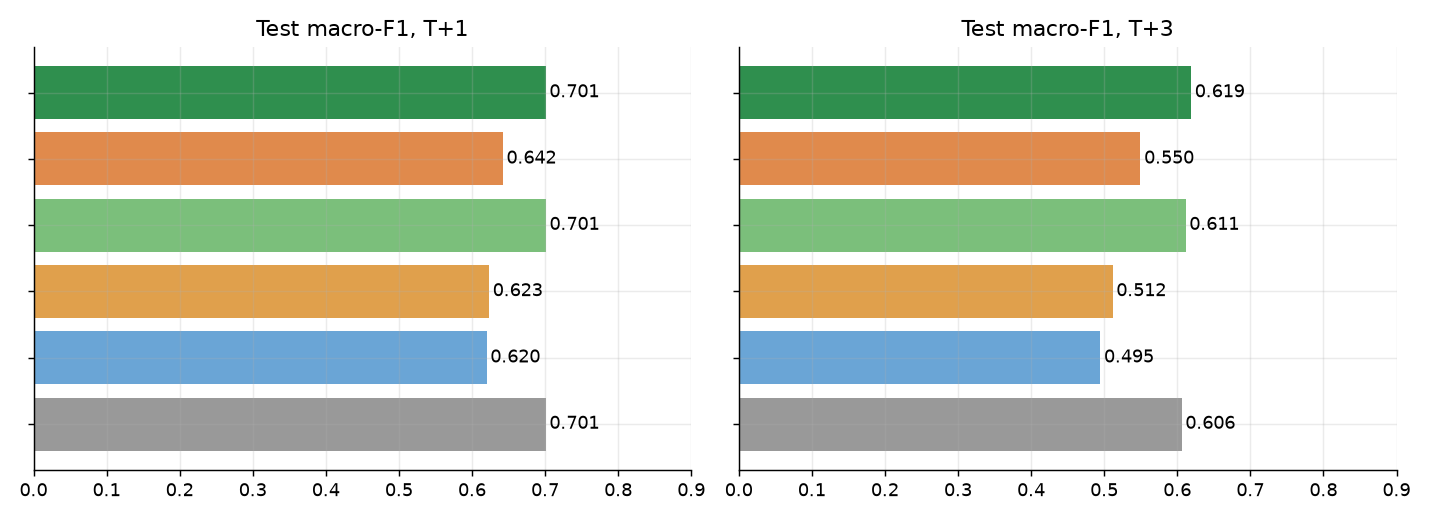

In [38]:
if RETRAIN: run("09_final_pipeline.py")
fc = pd.read_csv(TAB / "final_comparison.csv")
display(fc[["model", "horizon", "macro_f1", "bal_acc", "high_recall", "high_precision", "missed_high", "false_alarm", "ece", "coverage"]].round(3))
show("final_comparison.png")

## Step 7: lab experiments
The experiments from our lab proposal: (a) PR-AUC for all models, (b) attention vs simple concatenation, (c) one multi-task network vs separate networks for T+1 and T+3, and (d) walk-forward validation, where we train on the earlier years and test on the next year, for 2023 to 2026.

,model,horizon,macro_f1,pr_auc_macro,pr_auc_high,roc_auc_macro
0,Persistence,T+1,0.701,0.582,0.518,0.785
1,Rule(BPDB forecast),T+1,0.530,0.506,0.414,0.773
2,LogReg,T+1,0.442,0.624,0.642,0.808
3,RandomForest,T+1,0.643,0.689,0.668,0.881
4,XGBoost,T+1,0.620,0.702,0.671,0.877
5,"MM-GRU (3 seeds, calibrated)",T+1,0.623,0.679,0.674,0.862
6,Ensemble (train only),T+1,0.701,0.734,0.720,0.891
7,Persistence,T+3,0.606,0.490,0.372,0.713
8,Rule(BPDB forecast),T+3,0.474,0.457,0.335,0.714
9,LogReg,T+3,0.336,0.542,0.437,0.733


,model,horizon,macro_f1_mean,macro_f1_std,high_recall_mean,high_recall_std,high_precision_mean,high_precision_std,pr_auc_high_mean,pr_auc_high_std,missed_high_mean,missed_high_std,false_alarm_mean,false_alarm_std
0,"Attention fusion, multi-task (proposed)",T+1,0.593,0.046,0.760,0.069,0.459,0.053,0.645,0.041,215.333,61.785,816.000,166.096
1,"Attention fusion, multi-task (proposed)",T+3,0.499,0.011,0.690,0.038,0.312,0.014,0.437,0.012,277.333,34.020,1367.333,149.346
2,"Attention fusion, single-task",T+1,0.606,0.025,0.768,0.127,0.522,0.050,0.684,0.030,208.667,114.492,651.000,229.791
3,"Attention fusion, single-task",T+3,0.513,0.002,0.661,0.050,0.320,0.007,0.411,0.052,302.667,44.377,1256.333,122.280
4,"Concatenation fusion, multi-task",T+1,0.596,0.038,0.780,0.072,0.467,0.097,0.648,0.041,197.333,65.033,865.000,417.048
5,"Concatenation fusion, multi-task",T+3,0.516,0.010,0.753,0.064,0.325,0.021,0.478,0.070,220.667,56.959,1400.667,130.316


test_year                                     2023   2024   2025   2026
horizon model                                                          
T+1     Ensemble (val-tuned, + persistence)  0.566  0.618  0.628  0.691
        GRU + XGBoost (50/50)                0.524  0.621  0.532  0.652
        MM-GRU (3 seed avg)                  0.510  0.600  0.482  0.642
        Persistence                          0.623  0.689  0.641  0.671
        XGBoost                              0.484  0.615  0.537  0.640
T+3     Ensemble (val-tuned, + persistence)  0.448  0.542  0.527  0.608
        GRU + XGBoost (50/50)                0.428  0.541  0.435  0.582
        MM-GRU (3 seed avg)                  0.462  0.525  0.418  0.565
        Persistence                          0.545  0.570  0.532  0.590
        XGBoost                              0.396  0.521  0.441  0.565

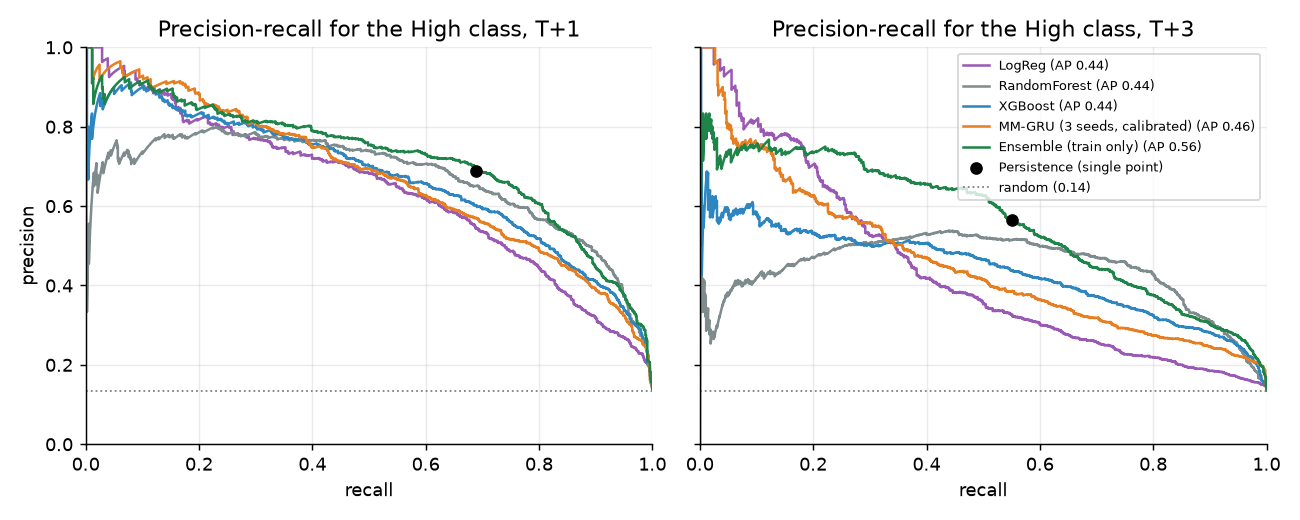

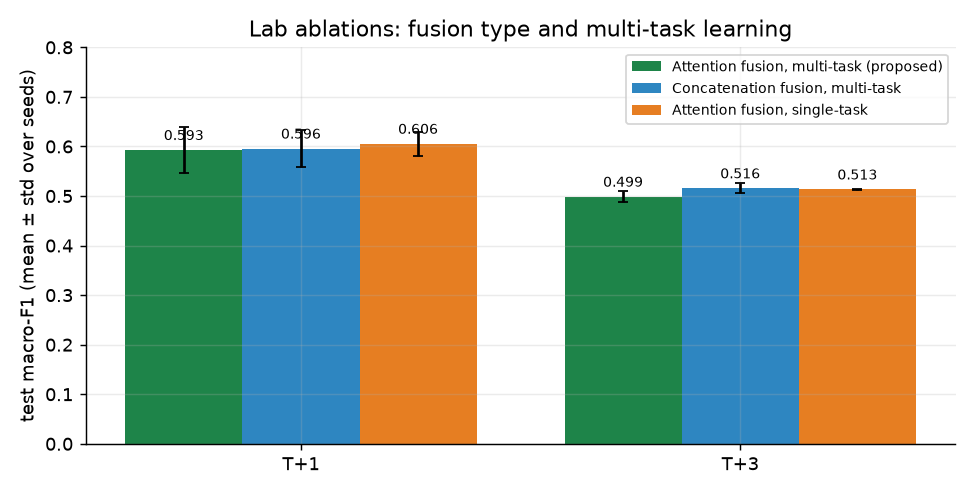

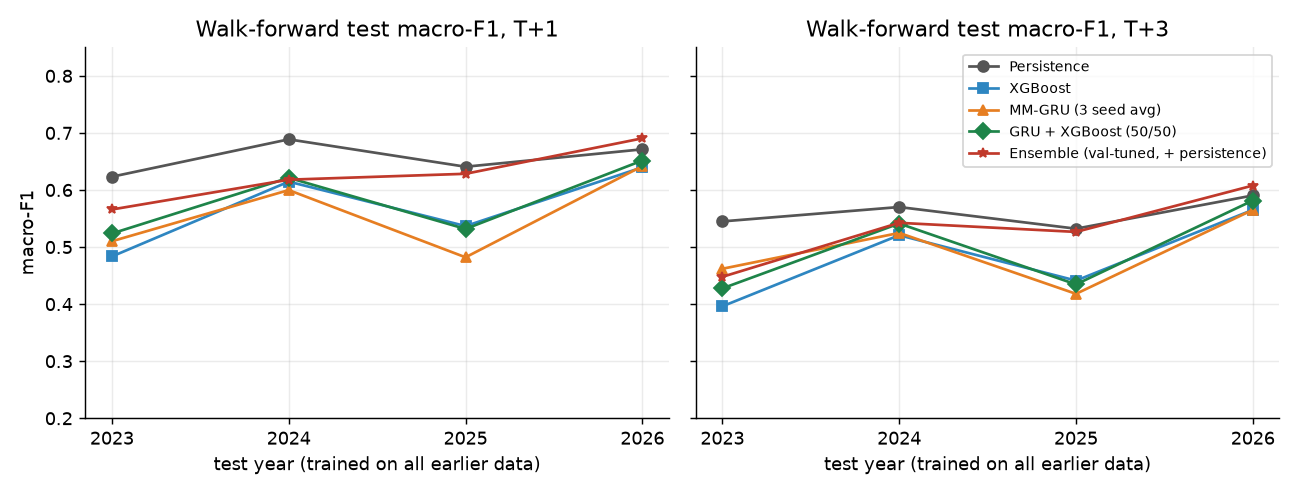

In [39]:
if RETRAIN: run("10_lab_experiments.py", *Q)
display(pd.read_csv(TAB / "lab_pr_auc.csv")[["model", "horizon", "macro_f1", "pr_auc_macro", "pr_auc_high", "roc_auc_macro"]].round(3))
display(pd.read_csv(TAB / "lab_fusion_task_summary.csv").round(3))
wf = pd.read_csv(TAB / "lab_walk_forward.csv")
display(wf.pivot_table(index=["horizon", "model"], columns="test_year", values="macro_f1").round(3))
show("lab_pr_curves.png", "lab_fusion_task.png", "lab_walk_forward.png", width=800)

## Step 8: forecast for any day
Change `AS_OF` to any date between 2019-12-04 and 2026-10-28. The saved GRU models (3 seeds) look at the 14 days before it and predict T+1 and T+3, and the table also shows what actually happened.


RISK ALERT - forecast made on 2026-07-15 using models: seeds [42, 43, 44]

      unit   T+1_date T+1_alert  T+1_confidence   T+3_date T+3_alert  T+3_confidence
  National 2026-07-16      High            0.68 2026-07-18 Uncertain            0.49
     Dhaka 2026-07-16    Medium            0.61 2026-07-18    Medium            0.56
Chattogram 2026-07-16 Uncertain            0.43 2026-07-18 Uncertain            0.42
  Rajshahi 2026-07-16 Uncertain            0.44 2026-07-18 Uncertain            0.43
Mymensingh 2026-07-16      High            0.75 2026-07-18      High            0.57
    Sylhet 2026-07-16      High            0.55 2026-07-18 Uncertain            0.41
  Barishal 2026-07-16 Uncertain            0.50 2026-07-18 Uncertain            0.49
   Rangpur 2026-07-16 Uncertain            0.50 2026-07-18 Uncertain            0.40
   Cumilla 2026-07-16 Uncertain            0.47 2026-07-18 Uncertain            0.40
    Khulna 2026-07-16      High            0.56 2026-07-18 Uncertain      

,unit,as_of,T+1_date,T+1_alert,T+1_best_guess,T+1_P(Low/Med/High),T+1_confidence,T+1_main_driver,T+1_actual,T+3_date,T+3_alert,T+3_best_guess,T+3_P(Low/Med/High),T+3_confidence,T+3_main_driver,T+3_actual
0,National,2026-07-15,2026-07-16,High,High,0.05/0.28/0.68,0.68,grid,High,2026-07-18,Uncertain,High,0.14/0.37/0.49,0.49,context,High
1,Dhaka,2026-07-15,2026-07-16,Medium,Medium,0.17/0.61/0.22,0.61,context,Medium,2026-07-18,Medium,Medium,0.21/0.56/0.22,0.56,context,Medium
2,Chattogram,2026-07-15,2026-07-16,Uncertain,Medium,0.23/0.43/0.34,0.43,context,Low,2026-07-18,Uncertain,Medium,0.32/0.42/0.26,0.42,context,Low
3,Rajshahi,2026-07-15,2026-07-16,Uncertain,High,0.15/0.41/0.44,0.44,context,Low,2026-07-18,Uncertain,Medium,0.24/0.43/0.32,0.43,context,Low
4,Mymensingh,2026-07-15,2026-07-16,High,High,0.03/0.22/0.75,0.75,grid,High,2026-07-18,High,High,0.11/0.31/0.57,0.57,context,High
5,Sylhet,2026-07-15,2026-07-16,High,High,0.14/0.31/0.55,0.55,context,Low,2026-07-18,Uncertain,High,0.23/0.36/0.41,0.41,context,Low
6,Barishal,2026-07-15,2026-07-16,Uncertain,Low,0.50/0.17/0.33,0.50,context,Low,2026-07-18,Uncertain,Low,0.49/0.20/0.31,0.49,context,Low
7,Rangpur,2026-07-15,2026-07-16,Uncertain,High,0.15/0.34/0.50,0.50,context,Medium,2026-07-18,Uncertain,High,0.24/0.36/0.40,0.40,context,Low
8,Cumilla,2026-07-15,2026-07-16,Uncertain,High,0.15/0.37/0.47,0.47,context,Medium,2026-07-18,Uncertain,Medium,0.25/0.40/0.36,0.40,context,Medium
9,Khulna,2026-07-15,2026-07-16,High,High,0.09/0.35/0.56,0.56,context,Medium,2026-07-18,Uncertain,Medium,0.18/0.42/0.40,0.42,context,Medium


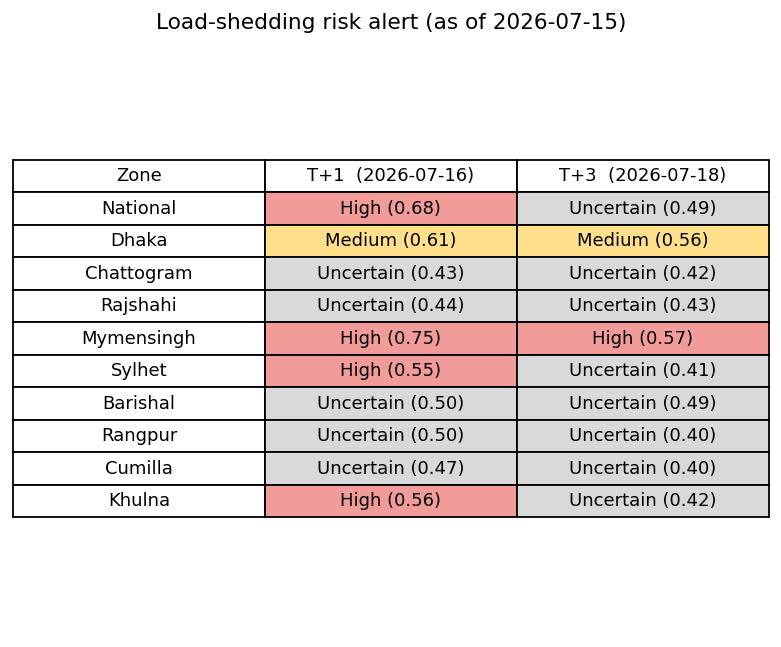

In [40]:
AS_OF = "2026-07-15"     # change this date
run("08_forecast_next_days.py", "--as-of", AS_OF)
display(pd.read_csv(TAB / f"forecast_{AS_OF}.csv"))
display(Image(str(FIG / f"forecast_{AS_OF}.png"), width=650))

## Latest alert
Forecast from the final ensemble using the newest BPDB report we have.

,unit,as_of,T+1_date,T+1_alert,T+1_best_guess,T+1_P(Low/Med/High),T+1_confidence,T+1_main_driver,T+3_date,T+3_alert,T+3_best_guess,T+3_P(Low/Med/High),T+3_confidence,T+3_main_driver
0,National,2026-10-28,2026-10-29,High,High,0.13/0.24/0.63,0.63,grid,2026-10-31,High,High,0.18/0.29/0.52,0.52,grid
1,Dhaka,2026-10-28,2026-10-29,Medium,Medium,0.14/0.73/0.13,0.73,context,2026-10-31,Medium,Medium,0.22/0.64/0.15,0.64,context
2,Chattogram,2026-10-28,2026-10-29,Medium,Medium,0.15/0.56/0.29,0.56,context,2026-10-31,Medium,Medium,0.26/0.49/0.25,0.49,context
3,Rajshahi,2026-10-28,2026-10-29,Medium,Medium,0.18/0.57/0.25,0.57,context,2026-10-31,Uncertain,Medium,0.25/0.46/0.29,0.46,context
4,Mymensingh,2026-10-28,2026-10-29,Uncertain,Medium,0.14/0.54/0.31,0.54,context,2026-10-31,Uncertain,Medium,0.19/0.46/0.35,0.46,context
5,Sylhet,2026-10-28,2026-10-29,Medium,Medium,0.17/0.58/0.26,0.58,context,2026-10-31,Medium,Medium,0.22/0.49/0.29,0.49,context
6,Barishal,2026-10-28,2026-10-29,Uncertain,Medium,0.19/0.49/0.32,0.49,context,2026-10-31,Uncertain,Medium,0.27/0.43/0.29,0.43,context
7,Rangpur,2026-10-28,2026-10-29,Medium,Medium,0.17/0.57/0.26,0.57,context,2026-10-31,Uncertain,Medium,0.24/0.47/0.28,0.47,context
8,Cumilla,2026-10-28,2026-10-29,Medium,Medium,0.14/0.57/0.30,0.57,grid,2026-10-31,Medium,Medium,0.22/0.50/0.28,0.50,grid
9,Khulna,2026-10-28,2026-10-29,Uncertain,Medium,0.16/0.51/0.33,0.51,context,2026-10-31,Uncertain,Medium,0.22/0.46/0.32,0.46,context


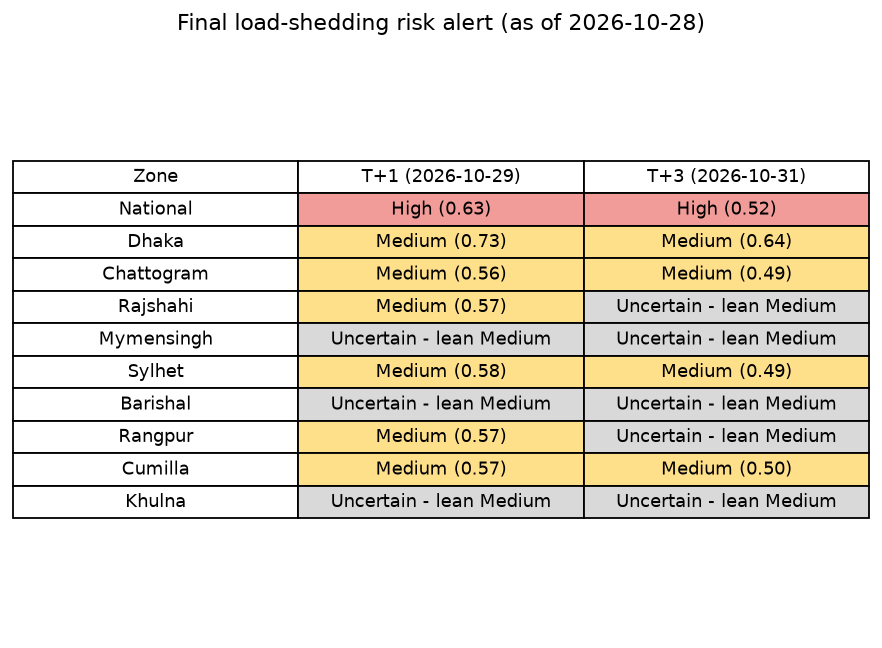

In [41]:
f = sorted(glob.glob(str(TAB / "forecast_final_*.csv")))[-1]
display(pd.read_csv(f)); display(Image(f.replace("tables", "figures").replace(".csv", ".png"), width=700))

In [42]:
# summary of all results + a zip of the outputs folder (it shows up in the Output tab)
run("07_report.py")
shutil.make_archive("/kaggle/working/loadshed_outputs" if Path("/kaggle/working").exists() else str(ROOT / "loadshed_outputs"), "zip", ROOT / "outputs")
display(Markdown((ROOT / "outputs" / "summary.md").read_text(encoding="utf-8")[:6000]))

written /kaggle/working/loadshed-early-warning/outputs/summary.md




# Results summary (auto-generated)

## 1. Main comparison (test set, all units pooled; neural rows = mean over seeds)

| model | horizon | macro_f1 | high_recall | high_precision | missed_high | false_alarm |
|---|---|---|---|---|---|---|
| Persistence | T+1 | 0.701 | 0.69 | 0.69 | 279.0 | 279.0 |
| Rule(BPDB forecast) | T+1 | 0.53 | 0.805 | 0.464 | 175.0 | 836.0 |
| LogReg | T+1 | 0.442 | 0.858 | 0.352 | 128.0 | 1420.0 |
| RandomForest | T+1 | 0.643 | 0.603 | 0.646 | 357.0 | 297.0 |
| XGBoost | T+1 | 0.62 | 0.527 | 0.658 | 425.0 | 246.0 |
| Persistence | T+3 | 0.606 | 0.551 | 0.564 | 401.0 | 381.0 |
| Rule(BPDB forecast) | T+3 | 0.474 | 0.702 | 0.397 | 266.0 | 952.0 |
| LogReg | T+3 | 0.336 | 0.668 | 0.254 | 297.0 | 1752.0 |
| RandomForest | T+3 | 0.451 | 0.1 | 0.357 | 805.0 | 160.0 |
| XGBoost | T+3 | 0.495 | 0.262 | 0.441 | 660.0 | 297.0 |
| MM-GRU calibrated | T+1 | 0.593 | 0.76 | 0.459 | 215.333 | 816.0 |
| MM-GRU calibrated | T+3 | 0.499 | 0.69 | 0.312 | 277.333 | 1367.333 |
| MM-GRU calibrated+abstain (kept only) | T+1 | 0.695 | 0.891 | 0.622 | 63.333 | 330.667 |
| MM-GRU calibrated+abstain (kept only) | T+3 | 0.569 | 0.778 | 0.393 | 126.667 | 672.0 |
| MM-GRU raw | T+1 | 0.593 | 0.76 | 0.459 | 215.333 | 816.0 |
| MM-GRU raw | T+3 | 0.499 | 0.69 | 0.312 | 277.333 | 1367.333 |

## 2. Calibration (lower is better)

| model | horizon | ece | brier |
|---|---|---|---|
| MM-GRU calibrated | T+1 | 0.04 | 0.424 |
| MM-GRU calibrated | T+3 | 0.061 | 0.505 |
| MM-GRU raw | T+1 | 0.123 | 0.458 |
| MM-GRU raw | T+3 | 0.184 | 0.572 |

## 3. Abstain option (kept predictions only)

| horizon | coverage | macro_f1 | high_recall | missed_high | false_alarm |
|---|---|---|---|---|---|
| T+1 | 0.631 | 0.695 | 0.891 | 63.333 | 330.667 |
| T+3 | 0.655 | 0.569 | 0.778 | 126.667 | 672.0 |

## 4. Modality ablation

| model | horizon | macro_f1 | high_recall | missed_high | false_alarm |
|---|---|---|---|---|---|
| FULL (grid+weather+context) | T+1 | 0.582 | 0.822 | 160 | 970 |
| FULL (grid+weather+context) | T+3 | 0.49 | 0.727 | 244 | 1459 |
| grid only | T+1 | 0.598 | 0.749 | 226 | 473 |
| grid only | T+3 | 0.509 | 0.686 | 281 | 671 |
| weather only | T+1 | 0.435 | 0.339 | 594 | 923 |
| weather only | T+3 | 0.397 | 0.484 | 461 | 1516 |
| context only | T+1 | 0.396 | 0.473 | 474 | 1669 |
| context only | T+3 | 0.378 | 0.396 | 540 | 1587 |
| without grid | T+1 | 0.477 | 0.533 | 420 | 1078 |
| without grid | T+3 | 0.46 | 0.601 | 357 | 1482 |
| without weather | T+1 | 0.575 | 0.839 | 145 | 1017 |
| without weather | T+3 | 0.49 | 0.641 | 321 | 1266 |
| without context | T+1 | 0.557 | 0.641 | 323 | 572 |
| without context | T+3 | 0.513 | 0.52 | 429 | 514 |

## 5. Leave-one-division-out

| zone | horizon | high_days | gru_pooled_f1 | gru_lodo_f1 | xgb_pooled_f1 | xgb_lodo_f1 | gru_pooled_high_recall | gru_lodo_high_recall |
|---|---|---|---|---|---|---|---|---|
| Dhaka | T+1 | 22 | 0.547 | 0.465 | 0.428 | 0.579 | 0.727 | 1.0 |
| Dhaka | T+3 | 22 | 0.454 | 0.342 | 0.398 | 0.524 | 0.182 | 0.364 |
| Chattogram | T+1 | 40 | 0.533 | 0.457 | 0.477 | 0.578 | 0.7 | 0.975 |
| Chattogram | T+3 | 40 | 0.463 | 0.433 | 0.395 | 0.462 | 0.425 | 0.725 |
| Rajshahi | T+1 | 70 | 0.508 | 0.501 | 0.448 | 0.491 | 0.814 | 0.8 |
| Rajshahi | T+3 | 69 | 0.399 | 0.41 | 0.36 | 0.45 | 0.696 | 0.638 |
| Mymensingh | T+1 | 210 | 0.554 | 0.539 | 0.623 | 0.506 | 0.914 | 0.705 |
| Mymensingh | T+3 | 210 | 0.454 | 0.399 | 0.487 | 0.421 | 0.824 | 0.367 |
| Sylhet | T+1 | 99 | 0.509 | 0.519 | 0.58 | 0.457 | 0.848 | 0.788 |
| Sylhet | T+3 | 99 | 0.408 | 0.372 | 0.423 | 0.363 | 0.768 | 0.313 |
| Barishal | T+1 | 65 | 0.472 | 0.357 | 0.527 | 0.467 | 0.677 | 0.831 |
| Barishal | T+3 | 64 | 0.42 | 0.318 | 0.47 | 0.365 | 0.375 | 0.844 |
| Rangpur | T+1 | 83 | 0.473 | 0.557 | 0.558 | 0.557 | 0.807 | 0.783 |
| Rangpur | T+3 | 82 | 0.371 | 0.423 | 0.449 | 0.379 | 0.707 | 0.622 |
| Cumilla | T+1 | 71 | 0.532 | 0.528 | 0.577 | 0.625 | 0.789 | 0.761 |
| Cumilla | T+3 | 70 | 0.393 | 0.435 | 0.434 | 0.483 | 0.743 | 0.529 |
| Khulna | T+1 | 84 | 0.498 | 0.581 | 0.51 | 0.553 | 0.833 | 0.833 |
| Khulna | T+3 | 83 | 0.416 | 0.463 | 0.414 | 0.451 | 0.819 | 0.807 |

## 6. SHAP share by modality (XGBoost, High class)

| horizon | context | grid | weather |
|---|---|---|---|
| T+1 | 0.188 | 0.652 | 0.16 |
| T+3 | 0.198 | 0.649 | 0.152 |

## 7. Mean modality attention (GRU)

| Unnamed: 0 | grid | weather | context |
|---|---|---|---|
| T+1 | 0.348 | 0.119 | 0.533 |
| T+3 | 0.29 | 0.097 | 0.613 |

## 8. Example alerts (Dhaka, last 14 test days)

| date | T+1_alert | T+1_confidence | T+1_true | T+1_top_modality | T+3_alert | T+3_confidence | T+3_true | T+3_top_modality |
|---|---|---|---|---|---|---|---|---|
| 2026-10-14 | High | 0.57 | Medium | grid | Uncertain | 0.45 | Medium | context |
| 2026-10-15 | Medium | 0.66 | Medium | context | Medium | 0.51 | Medium | context |
| 2026-10-16 | Uncertain | 0.49 | Medium | context | Uncertain | 0.45 | Medium | context |
| 2026-10-17 | Medium | 0.62 | Medium | context | Medium | 0.6 | Medium | context |
| 2026-10-18 | Medium | 0.64 | Medium | context | Medium | 0.55 | Medium | context |
| 2026-10-19 | Medium | 0.69 | Medium | context | Medium | 0.63 | Medium | context |
| 2026-10-20 | Medium | 0.72 | Medium | context | Medium | 0.68 | Low | context |
| 2026-10-21 | Medium | 0.7 | Medium | context | Medium | 0.54 | Medium | context |
| 2026-10-22 | Medium | 0.73 | Low | context | Medium | 0.58 | Medium | context |
| 2026-10-23 | Medium | 0.65 | Medium | context | Medium | 0.54 | Medium | context |
| 2026-10-24 | Medium | 0.69 | Medium | context | Medium | 0.56 | High | context |
| 2026-10-25 | Medium | 0.67 | Medium | context | Medium | 0.54 | Medium | context |
| 2026-10-26 | Medium | 0.61 | High | context | Medium | 0.58 | ? | context |
| 2026-10-27 | Medium | 0.53 | Medium | context | Medium | 0.65 | ? | context |

## 9. FINAL system (scripts/09): validation-tuned ensemble, refit, test 2025-2026

| model | horizon | macro_f1